# Práctica - Cambio de base y mínimos cuadrados

Existen problemas en los que no necesariamente el comportamiento de los variables es necesariamente lineal. Esta práctica busca mostrar el uso de mínimos cuadrados ordinarios para una función cuadrática.

## Actividad

1. Encontrar la línea que mejor ajuste a los datos empleando la solución de mínimos cuadrados.

## Función cuadrática

Suponemos un polinomio de grado dos con un atributo, esto es,

$$
y_{i}=f_{\mathbf{\theta}}(x) = \theta_{1}x_{1}^{2}+\epsilon,
$$

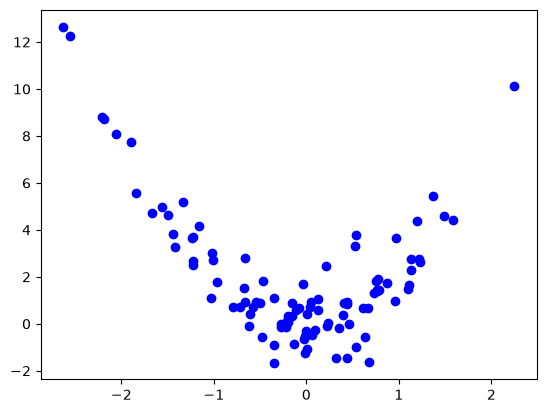

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# generamos datos artificialmente
X = np.random.normal(0, 1, size=(100,1))
Y = 2 * np.power(X,2) + np.random.normal(0,1,size=(100,1))

plt.scatter(X, Y, color="blue")
plt.savefig("grafica_p02.png", dpi=150, bbox_inches="tight")
plt.show()

## Solución

### Idea: cambio de base

Los datos siguen una parábola, así que una recta $\theta x$ no sirve. El truco es **cambiar de base**: en lugar de usar $x$, usamos $\phi(x) = x^2$ como nuestro nuevo atributo. Así el modelo $y = \theta_1 x^2$ vuelve a ser *lineal en los parámetros* y podemos usar la misma fórmula de mínimos cuadrados:

$$\boldsymbol{\theta} = (\boldsymbol{\Phi}^\top \boldsymbol{\Phi})^{-1} \boldsymbol{\Phi}^\top \mathbf{y}, \quad \boldsymbol{\Phi} = [x_1^2, x_2^2, \dots, x_N^2]^\top$$

In [10]:
# Cambio de base: x  ->  phi(x) = x^2
Phi = np.power(X, 2)

# Mínimos cuadrados sobre la nueva base
theta_cuad = np.linalg.inv(Phi.T.dot(Phi)).dot(Phi.T).dot(Y)
print("theta estimado (real = 2):", theta_cuad.ravel())

theta estimado (real = 2): [1.9297202]


In [11]:
# Para comparar: ajuste con una recta normal (sin cambio de base)
theta_recta = np.linalg.inv(X.T.dot(X)).dot(X.T).dot(Y)

ecm = lambda y, yp: np.mean((y - yp) ** 2)
print(f"ECM con recta y = theta*x:      {ecm(Y, X.dot(theta_recta)):.4f}")
print(f"ECM con cambio de base (x^2):   {ecm(Y, Phi.dot(theta_cuad)):.4f}")

ECM con recta y = theta*x:      9.5482
ECM con cambio de base (x^2):   0.9445


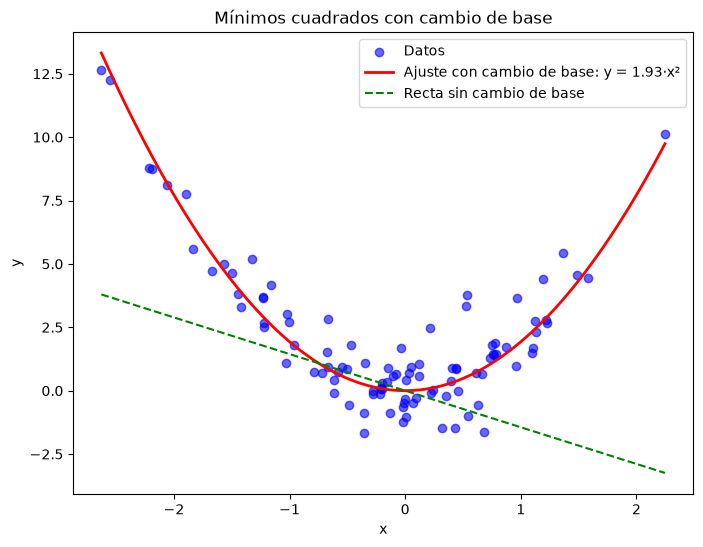

In [12]:
# Gráfica del ajuste
x_plot = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)

plt.figure(figsize=(8, 6))
plt.scatter(X, Y, color="blue", alpha=0.6, label="Datos")
plt.plot(x_plot, np.power(x_plot, 2).dot(theta_cuad), color="red", linewidth=2,
         label=f"Ajuste con cambio de base: y = {theta_cuad[0,0]:.2f}·x²")
plt.plot(x_plot, x_plot.dot(theta_recta), color="green", linestyle="--",
         label="Recta sin cambio de base")
plt.xlabel("x"); plt.ylabel("y")
plt.title("Mínimos cuadrados con cambio de base")
plt.legend(); 
plt.savefig("grafica_p02.png", dpi=150, bbox_inches="tight")
plt.show()

### Conclusión

La recta normal no puede captar la forma de parábola (su error es mucho mayor). Al cambiar de base a $x^2$, mínimos cuadrados recupera un parámetro cercano a 2, que es el valor real con el que se generaron los datos, y el error baja a casi la varianza del ruido (≈ 1).